In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("diabetes.csv")

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [7]:
#shape before cleanig
print(df.shape)

(768, 9)


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


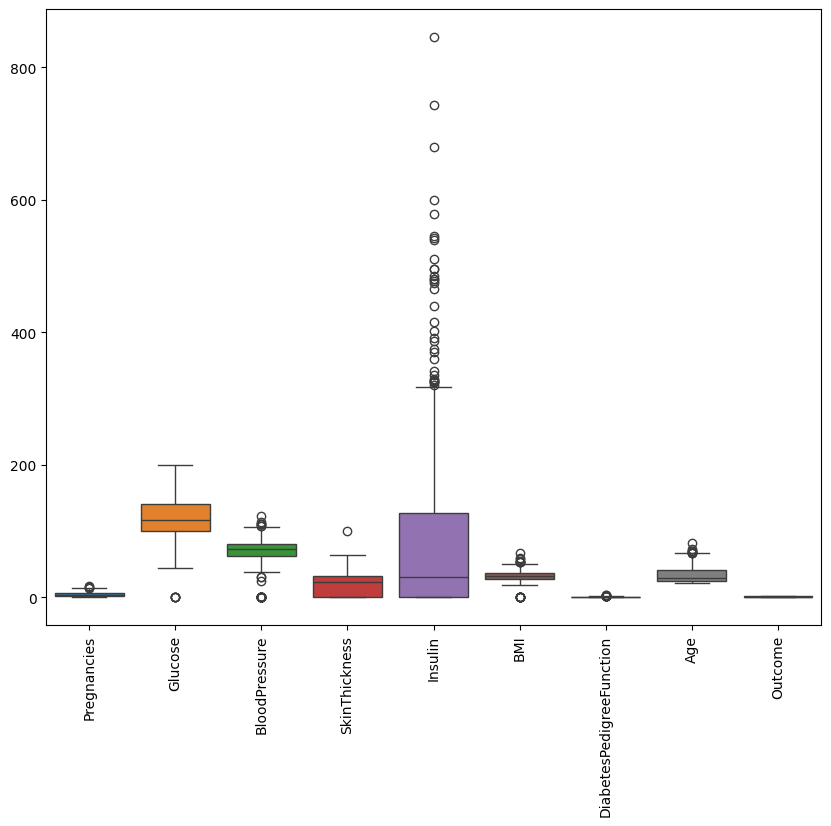

In [10]:
plt.figure(figsize=(10,8))
sns.boxplot(data=df)
plt.xticks(rotation=90)
plt.show()

In [11]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [12]:
columns_nan = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction']

In [13]:
df[columns_nan] = df[columns_nan].replace(0, np.nan) #converting zeroes into NaN value

In [14]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


<Axes: ylabel='BMI'>

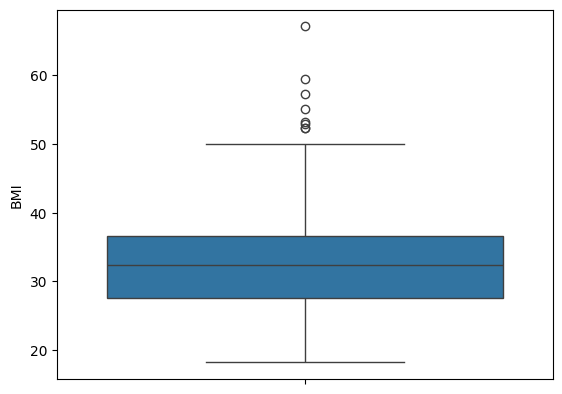

In [15]:
sns.boxplot(df['BMI']) #High BMI values can be medically possible.

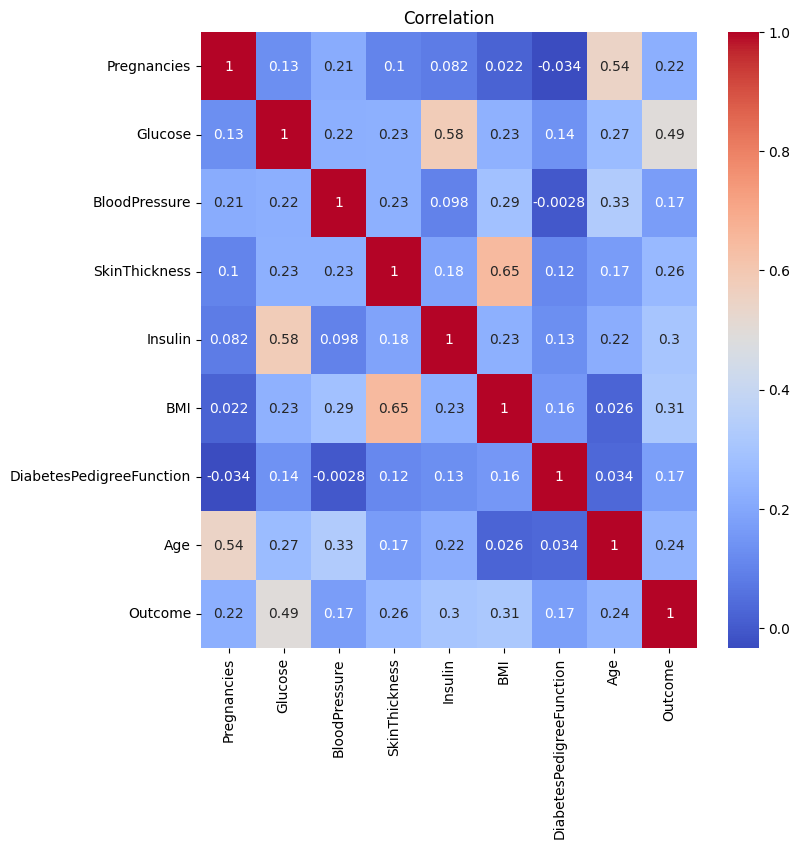

In [16]:
plt.figure(figsize=(8,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation')
plt.show()

Glucose is highly corelated to diebaties.

In [17]:
# col = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
#        'BMI', 'DiabetesPedigreeFunction', 'Age']
# df[col] = np.log1p(df[col])

In [18]:
#feature and target variable
x = df.drop('Outcome', axis=1)
y = df['Outcome']
print(x.shape, y.shape)

(768, 8) (768,)


In [19]:
#model training
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [20]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
x_train = pd.DataFrame(
    imputer.fit_transform(x_train),
    columns=x.columns,
    index=x_train.index
)
x_test = pd.DataFrame(
    imputer.transform(x_test),
    columns=x.columns,
    index=x_test.index
)

In [21]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [22]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight='balanced')
model.fit(x_train, y_train)

LogisticRegression(class_weight='balanced')

In [23]:
y_pred = model.predict(x_test)
print(y_pred)

[0 0 0 0 1 1 0 1 1 1 0 1 1 0 0 1 0 0 1 1 0 0 1 0 1 1 0 0 0 0 1 1 1 1 1 1 1
 0 1 1 0 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0 1 1 0 0 0
 0 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 1 1 1 0 1 0 1 0 1 1 1 0 0 1 0 1 0
 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 1 1 0 0 1 1 0 0 0 0 1 0 0 0 0
 1 1 0 1 0 0]


In [24]:
print("Training accuracy : ", model.score(x_train, y_train))
print("Testing accuracy : ", model.score(x_test, y_test))

Training accuracy :  0.758957654723127
Testing accuracy :  0.7012987012987013


Class 0 = No diabetes.

Class 1 = Diabetes.

In [25]:
from sklearn.metrics import accuracy_score, confusion_matrix , classification_report
print(classification_report(y_test, y_pred))
print("\nAccuracy : ", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix :")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.70      0.75        99
           1       0.57      0.71      0.63        55

    accuracy                           0.70       154
   macro avg       0.69      0.70      0.69       154
weighted avg       0.72      0.70      0.71       154


Accuracy :  0.7012987012987013

Confusion Matrix :
[[69 30]
 [16 39]]


In [26]:
from sklearn.metrics import roc_auc_score, roc_curve
y_prob = model.predict_proba(x_test)[:,1]
auc = roc_auc_score(y_test, y_prob)
print("AUC : ", auc)


AUC :  0.8214876033057851


In [27]:
coefficients = pd.DataFrame({
    'Features': x.columns,
    'Coefficients': model.coef_[0]})
coefficients = coefficients.sort_values(by='Coefficients', ascending=False)
coefficients

,Features,Coefficients
1,Glucose,1.134016
5,BMI,0.713623
7,Age,0.443094
6,DiabetesPedigreeFunction,0.239578
0,Pregnancies,0.237996
3,SkinThickness,0.069166
4,Insulin,-0.135560
2,BloodPressure,-0.168152


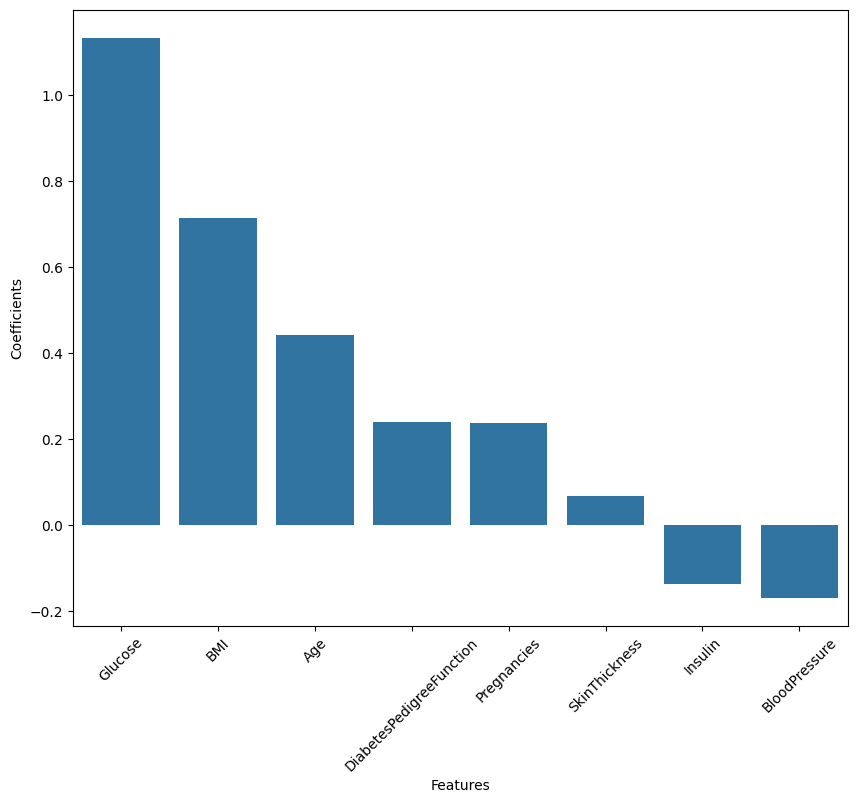

In [28]:
plt.figure(figsize=(10,8))
sns.barplot(data=coefficients, x='Features', y='Coefficients')
plt.xticks(rotation=45)
plt.show()